# Comparing authors by word frequency
Harrison Crettol, CS 445 Mini Project 1

My first idea was to compare two authors and find what words they both used the most. After thinking about it more, I realized that it would most likely result in the most commonly used words, such as, "the", "and", "a". So instead I'm looking at where authors differ.

I'm comparing three pairs that get progressively harder to tell apart:

1. Macbeth vs Romeo and Juliet (same author, so this is my baseline)
2. Shakespeare vs Dr. Seuss (should be easy)
3. Shakespeare vs Christopher Marlowe (should be hard)

Marlowe is the one I actually care about. He was born the same year as Shakespeare and wrote for the same theaters, so if word frequencies can still separate them then the method is picking up something real about the writing and not just the time period or the genre.

## Step 1: Get the books

Three plays download from Project Gutenberg, so anyone running this gets the same files I did. Green Eggs and Ham is from 1960 and still under copyright, so there is nowhere legitimate to download it. Mine is a transcription with typos, which makes it the weakest text here.

All three plays come from the same source on purpose. If I mixed editions, some of the differences I found would be the editors instead of the authors.

In [1]:
import os, re, math
from collections import Counter
import matplotlib.pyplot as plt
import requests
from scipy.stats import norm

os.makedirs("data", exist_ok=True)

SOURCES = {
    "shakespeare_macbeth.txt":      ("Macbeth",          1533),
    "shakespeare_romeo_juliet.txt": ("Romeo and Juliet", 1513),
    "marlowe_faustus.txt":          ("Doctor Faustus",    779),
}

for filename, (title, pg_id) in SOURCES.items():
    path = os.path.join("data", filename)
    if os.path.exists(path):
        print("already have", path)
        continue
    r = requests.get(f"https://www.gutenberg.org/cache/epub/{pg_id}/pg{pg_id}.txt", timeout=30)
    r.raise_for_status()
    with open(path, "w", encoding="utf-8") as f:
        f.write(r.text)
    print("downloaded", path)

already have data/shakespeare_macbeth.txt
already have data/shakespeare_romeo_juliet.txt
already have data/marlowe_faustus.txt


## Step 2: Clean the text and split it into words

Four things get removed before counting: the Gutenberg license text at the top and bottom of every file, the 175 editor's footnotes at the end of Faustus, anything in square brackets (stage directions), and the speaker name in front of every line, like "MACBETH.".

The footnotes mattered a lot. Before I cut them, the word most "characteristic of Marlowe" came out as **footnote**, plus fragments like "tos" from the editor writing "4tos". I was measuring the editor and not the author.

The speaker names were the same kind of problem. There are hundreds of them in each play, and they were pushing "witch", "nurse", and "scholar" to the top of my lists just because those characters talk a lot.

Then everything is lowercased so "The" and "the" count as one word, and apostrophes inside words are kept so "don't" stays whole.

In [2]:
def strip_gutenberg(text):
    start = re.search(r"\*\*\*\s*START OF TH[EIS]+ PROJECT GUTENBERG EBOOK.*?\*\*\*", text, re.I)
    end   = re.search(r"\*\*\*\s*END OF TH[EIS]+ PROJECT GUTENBERG EBOOK.*?\*\*\*", text, re.I)
    return text[(start.end() if start else 0):(end.start() if end else len(text))]

def strip_editorial(text):
    cut = re.search(r"^\s*FOOTNOTES:\s*$", text, re.M)
    if cut:
        text = text[:cut.start()]
    return re.sub(r"\[.*?\]", " ", text, flags=re.S)

def words_of(text):
    text = text.lower().replace("\u2019", "'")
    text = re.sub(r"\bth'", "the ", text)
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text)

def strip_speakers(text):
    # speaker names in capitals at the start of a line, like "MACBETH." or "FAUSTUS. Settle thy studies"
    return re.sub(r"^\s*[A-Z][A-Z '\-]*[A-Z]\.", " ", text, flags=re.M)

def load(path, play=True):
    with open(path, encoding="utf-8", errors="replace") as f:
        text = strip_editorial(strip_gutenberg(f.read()))
    if play:
        text = strip_speakers(text)   # skipped for Seuss, since his whole book is in capitals
    return words_of(text)

texts = {
    "Macbeth":            load("data/shakespeare_macbeth.txt"),
    "Romeo and Juliet":   load("data/shakespeare_romeo_juliet.txt"),
    "Doctor Faustus":     load("data/marlowe_faustus.txt"),
    "Green Eggs and Ham": load("data/seuss_green_eggs_and_ham.txt", play=False),
}

for name, w in texts.items():
    print(f"{name:<20} {len(w):>7,} words")

Macbeth               17,431 words
Romeo and Juliet      24,816 words
Doctor Faustus        11,814 words
Green Eggs and Ham       806 words


## Step 3: Counts don't compare, so use rates

Green Eggs and Ham is under a thousand words and Romeo and Juliet is about twenty five thousand. A word will appear more times in the longer book no matter what, so comparing counts only tells me which book is longer.

The fix is to divide by the length of the text. **Count divided by total words, times 10,000.** That is a percentage with a bigger denominator: 1017 per 10,000 is the same thing as 10.2%.

Think of it like miles per hour. You don't have to drive a full hour to be going 60 mph. Green Eggs and Ham doesn't have to be 10,000 words long to have a rate per 10,000 words. It's a pace, not a total.

The cell below prints the arithmetic for one word so I can see it happening.

In [3]:
# show the arithmetic for a single word, step by step
word = "not"
print(f'How the rate of "{word}" is calculated in each text:\n')
for name, w in texts.items():
    count = w.count(word)
    total = len(w)
    print(f"{name}")
    print(f"   appears {count} times out of {total:,} words")
    print(f"   {count} / {total:,} = {count/total:.4f}   which is {count/total*100:.1f}% of the text")
    print(f"   x 10,000 = {count/total*10000:.0f} per 10,000 words\n")

print("Note how much one single word is worth in each text:")
for name, w in texts.items():
    print(f"   {name:<20} one occurrence = {10000/len(w):5.2f} per 10,000")
print("\nThat is why short texts give jumpy numbers, and why Step 7 tests for luck.")

How the rate of "not" is calculated in each text:

Macbeth
   appears 165 times out of 17,431 words
   165 / 17,431 = 0.0095   which is 0.9% of the text
   x 10,000 = 95 per 10,000 words

Romeo and Juliet
   appears 259 times out of 24,816 words
   259 / 24,816 = 0.0104   which is 1.0% of the text
   x 10,000 = 104 per 10,000 words

Doctor Faustus
   appears 99 times out of 11,814 words
   99 / 11,814 = 0.0084   which is 0.8% of the text
   x 10,000 = 84 per 10,000 words

Green Eggs and Ham
   appears 82 times out of 806 words
   82 / 806 = 0.1017   which is 10.2% of the text
   x 10,000 = 1017 per 10,000 words

Note how much one single word is worth in each text:
   Macbeth              one occurrence =  0.57 per 10,000
   Romeo and Juliet     one occurrence =  0.40 per 10,000
   Doctor Faustus       one occurrence =  0.85 per 10,000
   Green Eggs and Ham   one occurrence = 12.41 per 10,000

That is why short texts give jumpy numbers, and why Step 7 tests for luck.


In [4]:
# now compute rates for every word in every text
def rate_table(words, per=10000):
    counts = Counter(words)
    n = len(words)
    return {w: cnt * per / n for w, cnt in counts.items()}, counts, n

rates, counts, totals = {}, {}, {}
for name, w in texts.items():
    rates[name], counts[name], totals[name] = rate_table(w)

# my original question: what are the most common words? same answer every time.
print("Most common words in each text (rate per 10,000):\n")
for name in texts:
    top = sorted(rates[name].items(), key=lambda kv: -kv[1])[:8]
    print(f"{name:<20}", "  ".join(f"{w} {r:.0f}" for w, r in top))

Most common words in each text (rate per 10,000):

Macbeth              the 445  and 321  to 218  of 203  i 195  a 154  that 131  in 130
Romeo and Juliet     and 291  the 274  i 233  to 218  a 196  of 158  my 143  that 139
Doctor Faustus       and 312  the 299  i 254  of 241  to 207  a 141  that 139  faustus 131
Green Eggs and Ham   i 1030  not 1017  them 732  a 695  like 546  in 496  do 459  you 422


Every text is topped by the same function words. That's why my first question was a dead end, and why the rest of this looks at differences instead.

## Step 4: Which words separate two texts?

For every word I compare its rate in one text against its rate in the other, and report how many times more often one text uses it. "36x more often" means exactly what it sounds like.

Two safeguards. I add 1 to each count so a word missing from one text doesn't divide by zero, and I ignore words appearing fewer than 10 times total so a rare word can't top the list on a fluke.

I also skip character and place names. "Macbeth" appears constantly in Macbeth, but that says nothing about how Shakespeare writes. Dropping them is my judgment call and I list it as a limitation.

In [5]:
# built by reading the output and adding whatever was obviously a name, a place, or a stage direction word
NAMES = {
    "macbeth","banquo","duncan","malcolm","donalbain","macduff","lennox","ross",
    "menteith","angus","caithness","fleance","siward","seyton","hecate","scotland",
    "cawdor","thane","dunsinane","birnam","glamis",
    "romeo","juliet","tybalt","mercutio","benvolio","capulet","montague","escalus",
    "laurence","lawrence","balthasar","sampson","gregory","peter","verona","mantua",
    "faustus","mephistopheles","mephistophilis","mephist","faust","wagner","lucifer",
    "belzebub","valdes","cornelius","wittenberg","robin","ralph","clown","courser",
    "sam","chorus","exeunt","exit","enter","scene","act",
    "capulet's","macbeth's","faustus'","juliet's","paris",
    "re",   # left over from "Re-enter" in the Faustus stage directions
}

def distinctive(name_a, name_b, min_total=10, top=8, vocab=None):
    ca, cb = counts[name_a], counts[name_b]
    na, nb = totals[name_a], totals[name_b]
    rows = []
    for w in set(ca) | set(cb):
        if w in NAMES or (vocab is not None and w not in vocab):
            continue
        if ca[w] + cb[w] < min_total:
            continue
        ra = (ca[w] + 1) / (na + 1) * 10000     # add 1 so nothing divides by zero
        rb = (cb[w] + 1) / (nb + 1) * 10000
        rows.append((ra / rb, w, ra, rb))
    rows.sort()
    return rows[-top:][::-1], rows[:top]

def show(name_a, name_b, **kw):
    hi, lo = distinctive(name_a, name_b, **kw)
    print(f"\n{name_a}  vs  {name_b}")
    print(f"\n  {name_a} uses these much more:")
    for ratio, w, ra, rb in hi:
        print(f"     {w:<12} {ratio:6.1f}x more often    ({ra:6.1f} vs {rb:5.1f} per 10k)")
    print(f"\n  {name_b} uses these much more:")
    for ratio, w, ra, rb in lo:
        print(f"     {w:<12} {1/ratio:6.1f}x more often    ({rb:6.1f} vs {ra:5.1f} per 10k)")

# baseline: same author, two different plays
show("Macbeth", "Romeo and Juliet")


Macbeth  vs  Romeo and Juliet

  Macbeth uses these much more:
     castle         37.0x more often    (  14.9 vs   0.4 per 10k)
     does           35.6x more often    (  14.3 vs   0.4 per 10k)
     has            28.5x more often    (  11.5 vs   0.4 per 10k)
     hail           25.6x more often    (  10.3 vs   0.4 per 10k)
     king           17.1x more often    (  20.7 vs   1.2 per 10k)
     england        17.1x more often    (   6.9 vs   0.4 per 10k)
     doctor         15.7x more often    (   6.3 vs   0.4 per 10k)
     cauldron       15.7x more often    (   6.3 vs   0.4 per 10k)

  Romeo and Juliet uses these much more:
     nurse          37.9x more often    (  21.8 vs   0.6 per 10k)
     friar          30.9x more often    (  17.7 vs   0.6 per 10k)
     cell           16.2x more often    (   9.3 vs   0.6 per 10k)
     banished       14.8x more often    (   8.5 vs   0.6 per 10k)
     married        14.0x more often    (   8.1 vs   0.6 per 10k)
     ah             11.9x more often

Even with the same author, the lists are mostly plot words: castle, king, and cauldron for Macbeth, and nurse, friar, banished, and married for Romeo and Juliet. These seem more related to what the plays are about than to style choices. The two that don't fit are "does" and "has", since those are grammar. I come back to them in Step 8.

## Step 5: The two-author comparisons

The hard case is Marlowe. The easy case is Seuss.

Seuss needs one adjustment. His whole vocabulary is 57 words, so "Shakespeare uses thousands of words Seuss never uses" is true but meaningless. I restrict that comparison to words Seuss actually uses, and ask whether Shakespeare uses those same words at different rates.

In [6]:
show("Macbeth", "Doctor Faustus")

seuss_vocab = set(texts["Green Eggs and Ham"])
print(f"\n\nRestricted to the {len(seuss_vocab)} words Seuss actually uses:")
show("Macbeth", "Green Eggs and Ham", vocab=seuss_vocab, min_total=15)


Macbeth  vs  Doctor Faustus

  Macbeth uses these much more:
     does           16.9x more often    (  14.3 vs   0.8 per 10k)
     worthy         12.2x more often    (  10.3 vs   0.8 per 10k)
     king           12.2x more often    (  20.7 vs   1.7 per 10k)
     hail           12.2x more often    (  10.3 vs   0.8 per 10k)
     son            11.5x more often    (   9.8 vs   0.8 per 10k)
     bloody         10.8x more often    (   9.2 vs   0.8 per 10k)
     wood            9.5x more often    (   8.0 vs   0.8 per 10k)
     sword           9.5x more often    (   8.0 vs   0.8 per 10k)

  Doctor Faustus uses these much more:
     ah             26.6x more often    (  15.2 vs   0.6 per 10k)
     devils         19.2x more often    (  11.0 vs   0.6 per 10k)
     fetch          19.2x more often    (  11.0 vs   0.6 per 10k)
     goblet         17.7x more often    (  10.2 vs   0.6 per 10k)
     years          17.7x more often    (  10.2 vs   0.6 per 10k)
     soul           14.2x more often    

Seuss was the easy one, like I expected, but not for an interesting reason. His top words (eat, them, like, could, would, not) are just the lines the book repeats over and over.

Marlowe was easier to separate than I expected, but mostly on plot words again: king, sword, and bloody for Macbeth, and devils, soul, book, and magic for Faustus. That's the same kind of thing that separated the two Shakespeare plays, so it doesn't really show a difference in authors. "does" showing up again is the only thing that looks like style.

## Step 6: Chart the hard comparison

Blue bars are words Macbeth uses more, red bars are words Faustus uses more. Further from zero means more lopsided. The scale is doubling: 1 step means twice as often, 2 steps means four times, 3 steps means eight times.

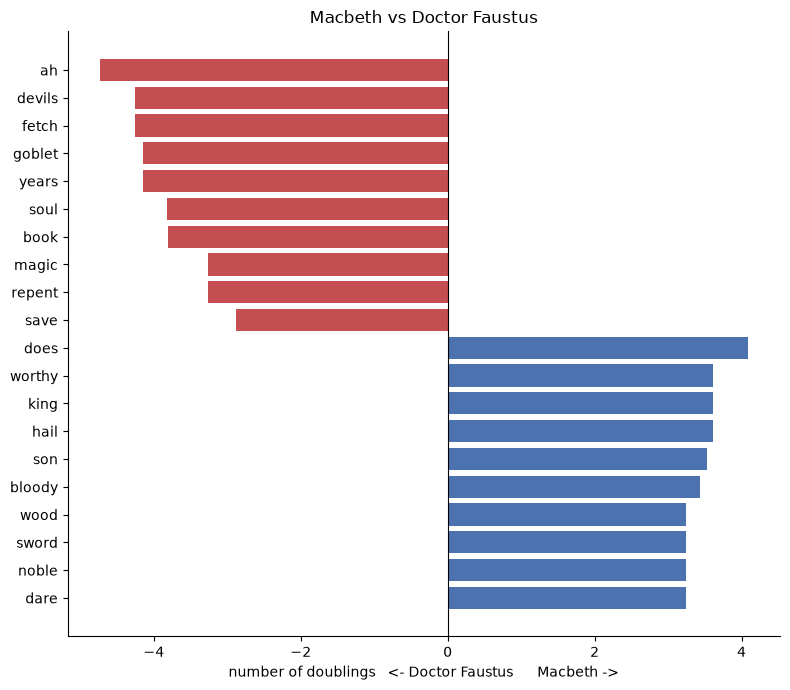

In [7]:
def plot_distinctive(name_a, name_b, top=10, **kw):
    hi, lo = distinctive(name_a, name_b, top=top, **kw)
    rows = list(reversed(hi)) + lo[::-1]
    scores = [math.log2(r[0]) for r in rows]

    fig, ax = plt.subplots(figsize=(8, 7))
    ax.barh(range(len(rows)), scores,
            color=["#4C72B0" if s > 0 else "#C44E52" for s in scores])
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([r[1] for r in rows])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel(f"number of doublings   <- {name_b}      {name_a} ->")
    ax.set_title(f"{name_a} vs {name_b}")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

plot_distinctive("Macbeth", "Doctor Faustus")

## Step 7: Is the difference real, or just luck? (extra credit)

A lopsided rate could happen by accident, especially in a short text where one word is worth 12 per 10,000.

The assignment's setup: treat every word in a text as a trial where, with probability p, that word is "would". The number of times "would" appears is then binomial, and p is estimated by (times it appears) / (total words). Comparing two texts is a two-proportion test.

What it returns is a **p-value**: the chance of seeing a gap this big if the two texts really used the word at the same rate. p = 0.30 means it happens 30% of the time by luck, so it's nothing. p = 0.002 means twice in a thousand, so something real is going on. Under 0.05 is the usual cutoff.

The row to watch is the same-author one. If two Shakespeare plays come out significantly different, then a significant difference can't be proof of different authors.

In [8]:
def plain_test(word, name_a, name_b):
    ca, cb = counts[name_a][word], counts[name_b][word]
    na, nb = totals[name_a], totals[name_b]
    pa, pb = ca / na, cb / nb
    ra, rb = pa * 10000, pb * 10000
    print(f'  {name_a} {ra:.1f} per 10k  vs  {name_b} {rb:.1f} per 10k')

    pooled = (ca + cb) / (na + nb)
    se = math.sqrt(pooled * (1 - pooled) * (1 / na + 1 / nb))
    if se == 0:
        print("     neither text uses this word\n")
        return

    p = 2 * norm.sf(abs((pa - pb) / se))
    higher = name_a if ra > rb else name_b
    hi, lo = max(ra, rb), min(ra, rb)
    if lo > 0:
        print(f"     {higher} uses it {hi/lo:.1f}x more often")
    else:
        print(f"     {higher} uses it and the other never uses it at all")
    if p < 0.05:
        print(f"     REAL DIFFERENCE: too big to be luck (p={p:.3g})\n")
    else:
        print(f"     no real difference: small enough to be luck (p={p:.2f})\n")

PAIRS = [
    ("Macbeth", "Romeo and Juliet"),      # same author
    ("Macbeth", "Doctor Faustus"),        # same era, different author
    ("Macbeth", "Green Eggs and Ham"),    # nothing in common
]

for word in ["would", "not", "the", "my", "does", "doth"]:
    print(f'========== "{word}" ==========')
    for a, b in PAIRS:
        plain_test(word, a, b)

========== "would" ==========
  Macbeth 27.0 per 10k  vs  Romeo and Juliet 21.8 per 10k
     Macbeth uses it 1.2x more often
     no real difference: small enough to be luck (p=0.28)

  Macbeth 27.0 per 10k  vs  Doctor Faustus 21.2 per 10k
     Macbeth uses it 1.3x more often
     no real difference: small enough to be luck (p=0.33)

  Macbeth 27.0 per 10k  vs  Green Eggs and Ham 335.0 per 10k
     Green Eggs and Ham uses it 12.4x more often
     REAL DIFFERENCE: too big to be luck (p=3.13e-41)

========== "not" ==========
  Macbeth 94.7 per 10k  vs  Romeo and Juliet 104.4 per 10k
     Romeo and Juliet uses it 1.1x more often
     no real difference: small enough to be luck (p=0.32)

  Macbeth 94.7 per 10k  vs  Doctor Faustus 83.8 per 10k
     Macbeth uses it 1.1x more often
     no real difference: small enough to be luck (p=0.34)

  Macbeth 94.7 per 10k  vs  Green Eggs and Ham 1017.4 per 10k
     Green Eggs and Ham uses it 10.7x more often
     REAL DIFFERENCE: too big to be luck (p=

The same-author row is the catch. Macbeth and Romeo and Juliet are both Shakespeare, but "the" and "my" still come out as real differences. So a real difference only means the two texts are different, not that the authors are.

It goes the other way too. Seuss never uses "does" and it still isn't a real difference, because 800 words is too short to tell. The test tells me whether a gap is luck, not who wrote it.

## Step 8: Following up on "does"

"does" kept showing up as characteristic of Macbeth against both other plays, and "has" did against Romeo and Juliet. Those aren't plot words like "king" or "castle", they're grammar, so I checked them against their old-fashioned versions "doth" and "hath".

In [9]:
print(f"{'':<22}" + "".join(f"{w:>10}" for w in ["does","doth","has","hath"]))
for name in texts:
    print(f"{name:<22}" + "".join(f"{rates[name].get(w, 0):10.1f}" for w in ["does","doth","has","hath"]))
print("\n(rates per 10,000 words)")
print("Romeo and Juliet ~1595, Doctor Faustus ~1592, Macbeth ~1606")

                            does      doth       has      hath
Macbeth                     13.8       3.4      10.9      29.3
Romeo and Juliet             0.0      18.9       0.0      25.8
Doctor Faustus               0.0       7.6       8.5      22.9
Green Eggs and Ham           0.0       0.0       0.0       0.0

(rates per 10,000 words)
Romeo and Juliet ~1595, Doctor Faustus ~1592, Macbeth ~1606


Macbeth is the only play that uses "does", and it uses "doth" the least. Romeo and Juliet never uses "does" or "has" at all, and Faustus uses "has" but not "does". So this isn't a clean Shakespeare vs Marlowe split. Macbeth is the odd one out. (All three still use "hath" more than "has".)

Things other than the author that could explain it:
- Macbeth is about ten years newer, and English was switching from "doth/hath" to "does/has" around 1600.
- Macbeth wasn't printed until 1623, after Shakespeare died, so whoever copied or printed it could have changed some words.
- Scholars think Thomas Middleton revised parts of Macbeth, and his writing is known for using "does" and "has".

## Findings

**What is the question?**
Can word frequencies tell two authors apart, even ones who wrote at the same time for the same theaters, like Shakespeare and Marlowe?

**What was the approach?**
I cleaned four texts, turned word counts into rates per 10,000 words, and found the words with the most lopsided rates for three pairs: two Shakespeare plays, Shakespeare vs Seuss, and Shakespeare vs Marlowe. Then I used a two-proportion test to check whether the differences were bigger than luck.

**What problems did I encounter?**
- The texts are very different lengths (800 vs about 25,000 words), so raw counts didn't work and I switched to rates.
- The Gutenberg license text was getting counted as part of every play.
- 175 editor's footnotes in Faustus made "footnote" look like Marlowe's most characteristic word.
- Speaker names like "MACBETH." were counted as words and pushed "witch" and "nurse" to the top.
- Character names still took over the lists, so I filtered them by hand.
- My tokenizer split "th'" into "th" (now turned into "the"), and "Re-enter" in the Faustus stage directions left a fake word "re" (now skipped).

**What results did I get?**
- Small function words top every text, so the most common words don't separate anyone.
- Seuss is easy to separate, but only because his book repeats a tiny vocabulary.
- Macbeth vs Faustus separates mostly on plot words, which is the same thing that separates two Shakespeare plays.
- Two Shakespeare plays still show real differences on common words like "the" and "my", so a real difference doesn't prove a different author.
- The one grammar difference I found, "does/has" vs "doth/hath", splits Macbeth from both other plays, not Shakespeare from Marlowe.

Overall, with one play per author, word frequencies mostly measured what each play is about, not who wrote it.

**What new ideas did this generate?**
- Use several plays per author so the plot words average out.
- Compare only small grammar words (the, and, of, but) since they don't depend on the story.
- Split Macbeth by scene and see if "does" and "has" cluster in the parts people think Middleton wrote.
- Check "does" vs "doth" across Shakespeare's plays in date order to see if he switched over time.